# UNet++ EfficientNet-B4 — Phát Hiện Vết Dầu Tràn Trên Ảnh SAR

| Thông tin | Chi tiết |
|-----------|----------|
| Model | UNet++ |
| Encoder | EfficientNet-B4 (pretrained ImageNet) |
| Dataset | `deep-sar-oil-spill-segmentation-refined` |
| Task | Binary Segmentation: background vs oil spill |
| Framework | PyTorch + segmentation_models_pytorch |
| Input size | `256 × 256` (resize từ ảnh gốc `416 × 416`) |
| GPU | Kaggle P100 (16 GB) |

---
**Cấu trúc Notebook (11 cell):**
1. Cài đặt thư viện và import
2. CONFIG tập trung
3. Fix seed
4. Load và EDA dataset
5. Pipeline tiền xử lý chung
6. Dataset class và DataLoader
7. Định nghĩa model UNet++
8. Training loop
9. Visualize quá trình train
10. Evaluation trên tập validation
11. Inference với API thống nhất

## Cell 1. Cài đặt thư viện và import

In [18]:
!pip install -q segmentation-models-pytorch albumentations opencv-python-headless

import os
import csv
import json
import random
from pathlib import Path
from typing import List, Optional, Tuple

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
from albumentations.pytorch import ToTensorV2
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

print(f'PyTorch   : {torch.__version__}')
print(f'SMP       : {smp.__version__}')
print(f'CUDA avail: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU       : {torch.cuda.get_device_name(0)}')
    print(f'VRAM      : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
print('\n✓ Tất cả thư viện đã được import thành công')

PyTorch   : 2.10.0+cu128
SMP       : 0.5.0
CUDA avail: True
GPU       : Tesla T4
VRAM      : 15.6 GB

✓ Tất cả thư viện đã được import thành công


## Cell 2. CONFIG tập trung

> **Quy ước bắt buộc:** Mọi hyperparameter, đường dẫn và ngưỡng phân lớp đều phải đọc từ `CONFIG`. Không hardcode bất kỳ giá trị nào ở các cell sau.

In [19]:
DATASET_ROOT = Path('/kaggle/input/datasets/bakhtiyar2222/deep-sar-oil-spill-segmentation-refined')

CONFIG = {
    "seed"            : 42,
    "model_name"      : "unetpp_efficientnetb4",
    "encoder_name"    : "efficientnet-b4",
    "encoder_weights" : "imagenet",
    "in_channels"     : 3,
    "classes"         : 1,
    "image_size"      : (256, 256),
    "threshold"       : 0.5,
    "augmentation_prob": 0.6,
    "batch_size"      : 16,
    "epochs"          : 60,
    "learning_rate"   : 5e-5,
    "weight_decay"    : 3e-4,
    "num_workers"     : 2,
    "loss_function"   : "BCEDiceLoss",
    "scheduler"               : "CosineAnnealingWarmRestarts",
    "T_0"                     : 10,
    "T_mult"                  : 2,
    "early_stopping_patience" : 15,
    "train_image_dir" : str(DATASET_ROOT / 'images' / 'images' / 'train'),
    "train_mask_dir"  : str(DATASET_ROOT / 'masks'  / 'masks'  / 'train'),
    "val_image_dir"   : str(DATASET_ROOT / 'images' / 'images' / 'val'),
    "val_mask_dir"    : str(DATASET_ROOT / 'masks'  / 'masks'  / 'val'),
    "checkpoint_dir"  : '/kaggle/working/checkpoints',
    "output_dir"      : '/kaggle/working/outputs',
    "save_every_n_epochs": 5,
}

Path(CONFIG['checkpoint_dir']).mkdir(parents=True, exist_ok=True)
Path(CONFIG['output_dir']).mkdir(parents=True, exist_ok=True)
(Path(CONFIG['output_dir']) / 'predictions').mkdir(parents=True, exist_ok=True)

print('Dataset paths:')
for key in ['train_image_dir', 'train_mask_dir', 'val_image_dir', 'val_mask_dir']:
    p = Path(CONFIG[key])
    exists = p.exists()
    count  = len(list(p.glob('*.png'))) if exists else 0
    print(f'  {key:18s}: exists={exists} | n_png={count}')

print(f'\nimage_size = {CONFIG["image_size"]}')
print(f'threshold  = {CONFIG["threshold"]}')
print(f'epochs     = {CONFIG["epochs"]}')
print(f'batch_size = {CONFIG["batch_size"]}')

Dataset paths:
  train_image_dir   : exists=True | n_png=6455
  train_mask_dir    : exists=True | n_png=6455
  val_image_dir     : exists=True | n_png=1615
  val_mask_dir      : exists=True | n_png=1615

image_size = (256, 256)
threshold  = 0.5
epochs     = 60
batch_size = 16


## Cell 3. Fix seed

In [20]:
def seed_everything(seed: int) -> None:
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False
    print(f'✓ Seed cố định: {seed}')

seed_everything(CONFIG['seed'])
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'✓ Device: {DEVICE}')

✓ Seed cố định: 42
✓ Device: cuda


## Cell 4. Load và EDA dataset

Kiểm tra cấu trúc thư mục, số lượng ảnh-mask, kích thước gốc, giá trị mask và mức độ mất cân bằng lớp.

**Kiểm tra cần đạt:**
```
SAR image shape: (416, 416, 3)
Mask shape:      (416, 416)
Mask values:     {0, 1} hoặc {0, 255}
```

In [21]:
def load_image_mask_paths(image_dir: str, mask_dir: str) -> Tuple[List[Path], List[Path]]:
    image_paths = sorted(Path(image_dir).glob('*.png'))
    mask_paths  = sorted(Path(mask_dir).glob('*.png'))
    img_names   = {p.name for p in image_paths}
    mask_names  = {p.name for p in mask_paths}
    mismatch    = img_names - mask_names
    if mismatch:
        print(f'  ⚠ {len(mismatch)} ảnh không có mask tương ứng')
    else:
        print(f'  ✓ Tất cả {len(image_paths)} ảnh có mask tương ứng')
    return image_paths, mask_paths

print('=== Load train set ===')
train_imgs, train_masks = load_image_mask_paths(CONFIG['train_image_dir'], CONFIG['train_mask_dir'])
print('=== Load val set ===')
val_imgs, val_masks = load_image_mask_paths(CONFIG['val_image_dir'], CONFIG['val_mask_dir'])
print(f'\nTrain: {len(train_imgs)} ảnh | Val: {len(val_imgs)} ảnh')

=== Load train set ===
  ✓ Tất cả 6455 ảnh có mask tương ứng
=== Load val set ===
  ✓ Tất cả 1615 ảnh có mask tương ứng

Train: 6455 ảnh | Val: 1615 ảnh


In [22]:
def compute_dataset_stats(image_paths: List[Path], n_sample: int = 100) -> dict:
    sample = image_paths[:n_sample]
    heights, widths, means = [], [], []
    for p in sample:
        img = cv2.imread(str(p))
        if img is not None:
            heights.append(img.shape[0])
            widths.append(img.shape[1])
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)
            means.append(gray.mean())
    return {
        'height_min': int(np.min(heights)), 'height_max': int(np.max(heights)),
        'width_min' : int(np.min(widths)),  'width_max' : int(np.max(widths)),
        'n_channels': cv2.imread(str(image_paths[0])).shape[2] if image_paths else 0,
        'mean_intensity': float(np.mean(means)),
        'std_intensity' : float(np.std(means)),
    }

def compute_oil_ratios(mask_paths: List[Path], n_sample: int = 500) -> List[float]:
    ratios = []
    for p in mask_paths[:n_sample]:
        msk = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
        if msk is not None:
            ratios.append((msk > 127).sum() / msk.size)
    return ratios

print('Calculating dataset stats...')
stats      = compute_dataset_stats(train_imgs)
oil_ratios = compute_oil_ratios(train_masks)

print(f'\n── Kích thước ảnh gốc (train):')
print(f'   H: [{stats["height_min"]}, {stats["height_max"]}]  W: [{stats["width_min"]}, {stats["width_max"]}]')
print(f'   Số kênh: {stats["n_channels"]}')
print(f'\n── Pixel intensity:')
print(f'   Mean: {stats["mean_intensity"]:.1f}  |  Std: {stats["std_intensity"]:.1f}')
print(f'\n── Oil ratio (train, {len(oil_ratios)} mẫu):')
print(f'   Mean: {np.mean(oil_ratios)*100:.2f}%  |  Max: {np.max(oil_ratios)*100:.2f}%')
print(f'   Ảnh có dầu: {sum(r > 0 for r in oil_ratios)} / {len(oil_ratios)}')

test_mask = cv2.imread(str(train_masks[0]), cv2.IMREAD_GRAYSCALE)
print(f'\n── Giá trị mask (mẫu): {sorted(np.unique(test_mask).tolist())}')

Calculating dataset stats...

── Kích thước ảnh gốc (train):
   H: [256, 256]  W: [256, 256]
   Số kênh: 3

── Pixel intensity:
   Mean: 132.4  |  Std: 24.7

── Oil ratio (train, 500 mẫu):
   Mean: 16.00%  |  Max: 93.33%
   Ảnh có dầu: 485 / 500

── Giá trị mask (mẫu): [0, 255]


  → Đã lưu: /kaggle/working/outputs/eda_samples.png


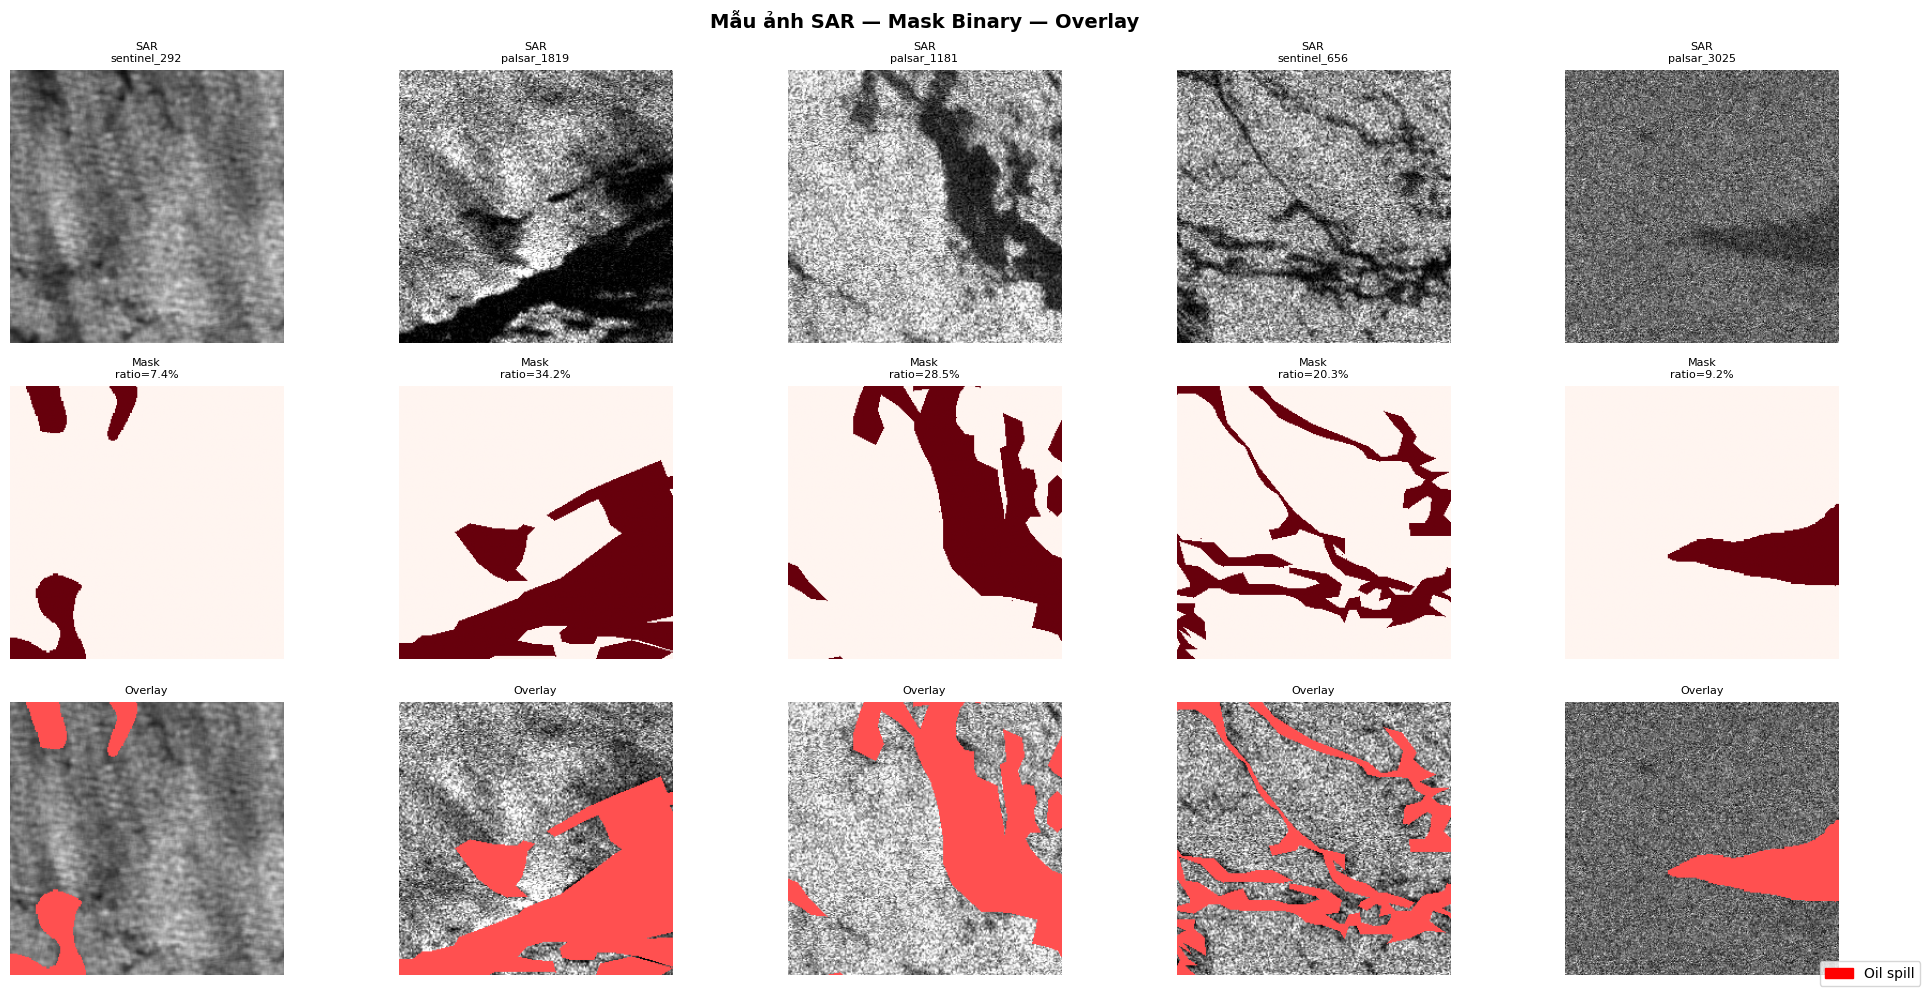

In [23]:
def show_eda_samples(img_paths, mask_paths, n=5, save_path=None):
    indices = random.sample(range(len(img_paths)), min(n, len(img_paths)))
    fig, axes = plt.subplots(3, len(indices), figsize=(4 * len(indices), 10))

    for col, idx in enumerate(indices):
        img_bgr = cv2.imread(str(img_paths[idx]))
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        msk     = cv2.imread(str(mask_paths[idx]), cv2.IMREAD_GRAYSCALE)
        binary  = (msk > 127).astype(np.uint8)
        ratio   = binary.sum() / binary.size

        axes[0, col].imshow(img_rgb)
        axes[0, col].set_title(f'SAR\n{img_paths[idx].stem[:12]}', fontsize=8)
        axes[0, col].axis('off')

        axes[1, col].imshow(binary, cmap='Reds', vmin=0, vmax=1)
        axes[1, col].set_title(f'Mask\nratio={ratio*100:.1f}%', fontsize=8)
        axes[1, col].axis('off')

        overlay = img_rgb.copy()
        overlay[binary == 1] = [255, 80, 80]
        axes[2, col].imshow(overlay)
        axes[2, col].set_title('Overlay', fontsize=8)
        axes[2, col].axis('off')

    patch = mpatches.Patch(color='red', label='Oil spill')
    fig.legend(handles=[patch], loc='lower right', fontsize=10)
    fig.suptitle('Mẫu ảnh SAR — Mask Binary — Overlay', fontsize=14, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight')
        print(f'  → Đã lưu: {save_path}')
    plt.show()

show_eda_samples(
    train_imgs, train_masks, n=5,
    save_path=str(Path(CONFIG['output_dir']) / 'eda_samples.png'),
)

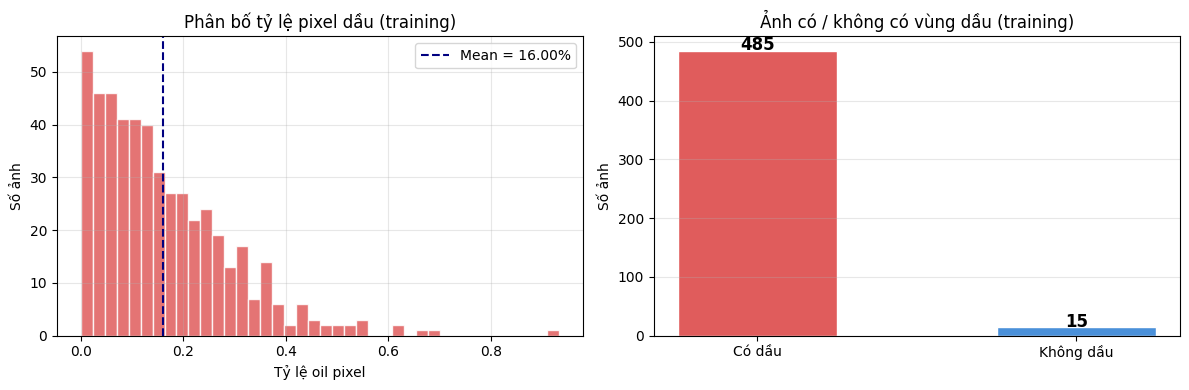

Class imbalance (no_oil/has_oil): 0.03x


In [24]:
has_oil    = sum(1 for r in oil_ratios if r > 0)
no_oil     = len(oil_ratios) - has_oil
mean_ratio = np.mean(oil_ratios)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(oil_ratios, bins=40, color='#e05c5c', edgecolor='white', alpha=0.85)
axes[0].axvline(mean_ratio, color='navy', linestyle='--', linewidth=1.5,
                label=f'Mean = {mean_ratio*100:.2f}%')
axes[0].set_title('Phân bố tỷ lệ pixel dầu (training)', fontsize=12)
axes[0].set_xlabel('Tỷ lệ oil pixel')
axes[0].set_ylabel('Số ảnh')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

bars = axes[1].bar(
    ['Có dầu', 'Không dầu'], [has_oil, no_oil],
    color=['#e05c5c', '#4a90d9'], edgecolor='white', width=0.5
)
for bar, v in zip(bars, [has_oil, no_oil]):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
        str(v), ha='center', fontweight='bold', fontsize=12,
    )
axes[1].set_title('Ảnh có / không có vùng dầu (training)', fontsize=12)
axes[1].set_ylabel('Số ảnh')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(str(Path(CONFIG['output_dir']) / 'class_distribution.png'), dpi=120)
plt.show()
print(f'Class imbalance (no_oil/has_oil): {no_oil / max(has_oil, 1):.2f}x')

## Cell 5. Pipeline tiền xử lý chung

Một pipeline Albumentations duy nhất được dùng cho **train, validation, test và inference**.

| Bước | Train | Val / Inference |
|---|:---:|:---:|
| Resize 256×256 | ✓ | ✓ |
| HorizontalFlip | ✓ | — |
| VerticalFlip | ✓ | — |
| RandomRotate90 | ✓ | — |
| ShiftScaleRotate | ✓ | — |
| RandomBrightnessContrast | ✓ | — |
| GaussNoise | ✓ | — |
| GaussianBlur | ✓ | — |
| CoarseDropout | ✓ | — |
| Normalize (ImageNet) | ✓ | ✓ |
| ToTensorV2 | ✓ | ✓ |

In [25]:
def build_transforms(is_train: bool = False) -> A.Compose:
    H, W = CONFIG['image_size']
    transforms = [A.Resize(height=H, width=W)]

    if is_train:
        prob = CONFIG['augmentation_prob']
        transforms.extend([
            A.HorizontalFlip(p=prob),
            A.VerticalFlip(p=prob),
            A.RandomRotate90(p=prob),
            A.ShiftScaleRotate(
                shift_limit=0.05, scale_limit=0.1, rotate_limit=15,
                border_mode=cv2.BORDER_CONSTANT, value=0, p=prob,
            ),
            A.OneOf([
                A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=1.0),
                A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=20, val_shift_limit=20, p=1.0),
            ], p=prob),
            A.GaussNoise(var_limit=(5.0, 30.0), p=prob),
            A.GaussianBlur(blur_limit=(3, 5), p=prob),
            A.CoarseDropout(
                max_holes=4, max_height=32, max_width=32,
                min_holes=1, fill_value=0, mask_fill_value=0, p=prob,
            ),
        ])

    transforms.extend([
        A.Normalize(
            mean=(0.485, 0.456, 0.406),
            std =(0.229, 0.224, 0.225),
        ),
        ToTensorV2(),
    ])
    return A.Compose(transforms)

TRAIN_TRANSFORM     = build_transforms(is_train=True)
INFERENCE_TRANSFORM = build_transforms(is_train=False)

print('✓ TRAIN_TRANSFORM:')
for t in TRAIN_TRANSFORM.transforms:
    print(f'  → {type(t).__name__}')
print('\n✓ INFERENCE_TRANSFORM:')
for t in INFERENCE_TRANSFORM.transforms:
    print(f'  → {type(t).__name__}')

✓ TRAIN_TRANSFORM:
  → Resize
  → HorizontalFlip
  → VerticalFlip
  → RandomRotate90
  → ShiftScaleRotate
  → OneOf
  → GaussNoise
  → GaussianBlur
  → CoarseDropout
  → Normalize
  → ToTensorV2

✓ INFERENCE_TRANSFORM:
  → Resize
  → Normalize
  → ToTensorV2


/tmp/ipykernel_58/2740125802.py:11: UserWarning: Argument(s) 'value' are not valid for transform ShiftScaleRotate
  A.ShiftScaleRotate(
/tmp/ipykernel_58/2740125802.py:19: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(5.0, 30.0), p=prob),
/tmp/ipykernel_58/2740125802.py:21: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, fill_value, mask_fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(


  → Đã lưu: /kaggle/working/outputs/augmentation_samples.png


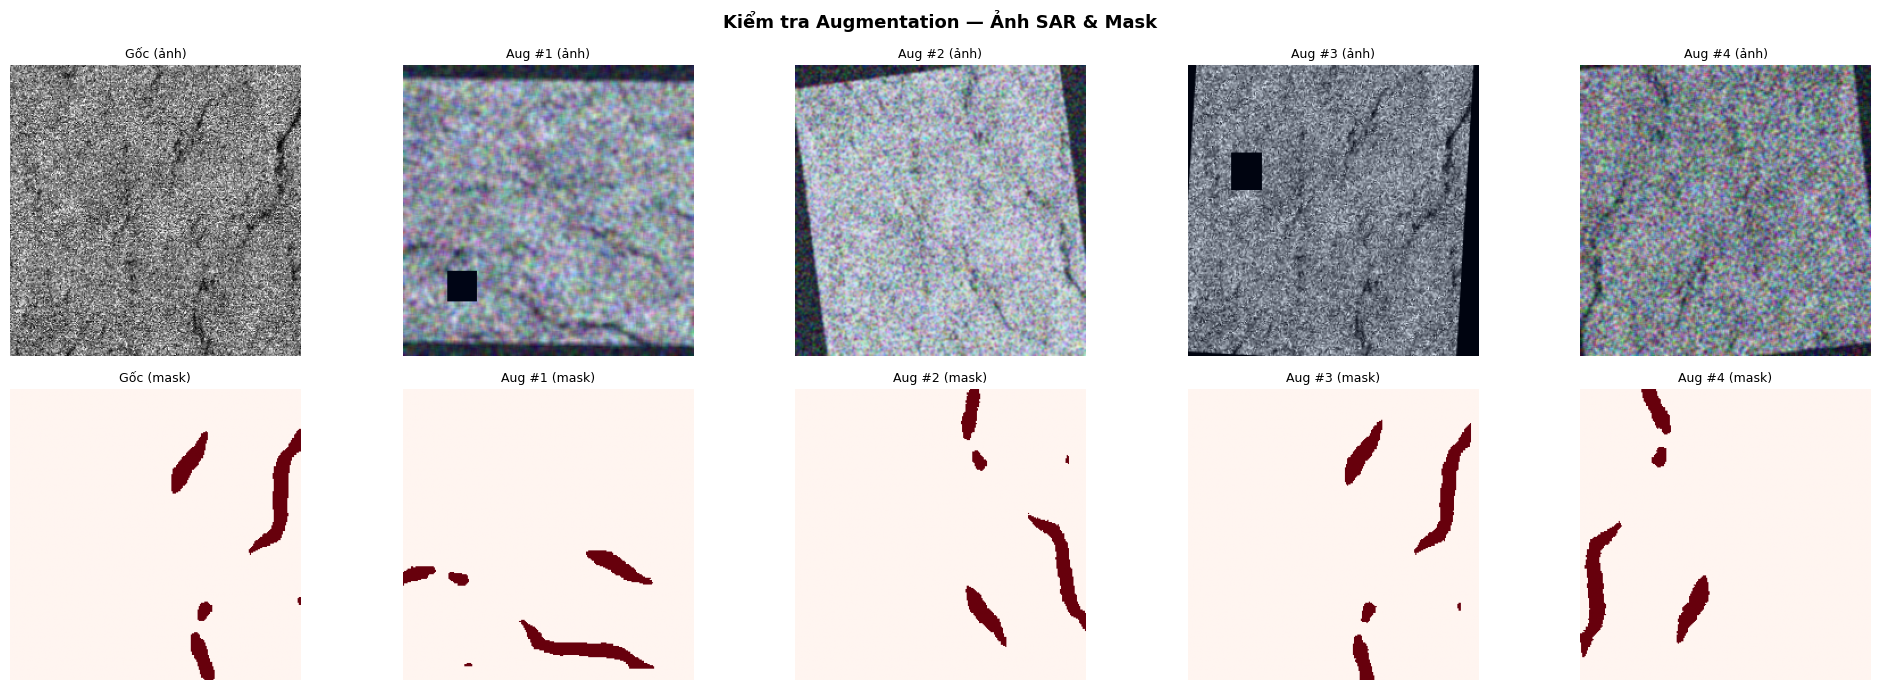

In [26]:
def visualize_augmentations(img_paths, mask_paths, n_aug=4, save_path=None):
    idx     = random.randint(0, len(img_paths) - 1)
    img_bgr = cv2.imread(str(img_paths[idx]))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    msk     = cv2.imread(str(mask_paths[idx]), cv2.IMREAD_GRAYSCALE)
    binary  = (msk > 127).astype(np.uint8)

    fig, axes = plt.subplots(2, n_aug + 1, figsize=(4 * (n_aug + 1), 7))

    axes[0, 0].imshow(img_rgb)
    axes[0, 0].set_title('Gốc (ảnh)', fontsize=9)
    axes[0, 0].axis('off')
    axes[1, 0].imshow(binary, cmap='Reds', vmin=0, vmax=1)
    axes[1, 0].set_title('Gốc (mask)', fontsize=9)
    axes[1, 0].axis('off')

    for i in range(n_aug):
        aug     = TRAIN_TRANSFORM(image=img_rgb, mask=binary)
        aug_img = aug['image'].permute(1, 2, 0).numpy()
        aug_img = (aug_img - aug_img.min()) / (aug_img.max() - aug_img.min() + 1e-8)
        aug_msk = aug['mask'].numpy()

        axes[0, i + 1].imshow(aug_img)
        axes[0, i + 1].set_title(f'Aug #{i+1} (ảnh)', fontsize=9)
        axes[0, i + 1].axis('off')
        axes[1, i + 1].imshow(aug_msk, cmap='Reds', vmin=0, vmax=1)
        axes[1, i + 1].set_title(f'Aug #{i+1} (mask)', fontsize=9)
        axes[1, i + 1].axis('off')

    fig.suptitle('Kiểm tra Augmentation — Ảnh SAR & Mask', fontsize=13, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight')
        print(f'  → Đã lưu: {save_path}')
    plt.show()

visualize_augmentations(
    train_imgs, train_masks, n_aug=4,
    save_path=str(Path(CONFIG['output_dir']) / 'augmentation_samples.png'),
)

## Cell 6. Dataset class và DataLoader

In [27]:
class OilSpillDataset(Dataset):
    def __init__(self, image_paths, mask_paths=None, transform=None):
        self.image_paths = image_paths
        self.mask_paths  = mask_paths
        self.transform   = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        img_bgr = cv2.imread(str(self.image_paths[index]))
        image   = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        mask = None
        if self.mask_paths is not None:
            msk  = cv2.imread(str(self.mask_paths[index]), cv2.IMREAD_GRAYSCALE)
            mask = (msk > 127).astype(np.float32)

        if self.transform is not None:
            if mask is not None:
                transformed = self.transform(image=image, mask=mask)
                image = transformed['image']
                mask  = transformed['mask'].unsqueeze(0).float()
            else:
                image = self.transform(image=image)['image']

        if mask is None:
            return image
        return image, mask


train_dataset = OilSpillDataset(train_imgs, train_masks, transform=TRAIN_TRANSFORM)
val_dataset   = OilSpillDataset(val_imgs,   val_masks,   transform=INFERENCE_TRANSFORM)

train_loader = DataLoader(
    train_dataset, batch_size=CONFIG['batch_size'], shuffle=True,
    num_workers=CONFIG['num_workers'], pin_memory=True, drop_last=True,
)
val_loader = DataLoader(
    val_dataset, batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=CONFIG['num_workers'], pin_memory=True,
)

print(f'Train dataset: {len(train_dataset)} mẫu  ({len(train_loader)} batch)')
print(f'Val   dataset: {len(val_dataset)} mẫu  ({len(val_loader)} batch)')

images, masks = next(iter(train_loader))
print(f'\nBatch images: {tuple(images.shape)}  (kỳ vọng: B×3×256×256)')
print(f'Batch masks : {tuple(masks.shape)}   (kỳ vọng: B×1×256×256)')
assert images.shape[1:] == (3, 256, 256)
assert masks.shape[1:]  == (1, 256, 256)
print('✓ Shape batch hợp lệ')

Train dataset: 6455 mẫu  (403 batch)
Val   dataset: 1615 mẫu  (101 batch)

Batch images: (16, 3, 256, 256)  (kỳ vọng: B×3×256×256)
Batch masks : (16, 1, 256, 256)   (kỳ vọng: B×1×256×256)
✓ Shape batch hợp lệ


## Cell 7. Định nghĩa model UNet++

In [28]:
model = smp.UnetPlusPlus(
    encoder_name    = CONFIG['encoder_name'],
    encoder_weights = CONFIG['encoder_weights'],
    in_channels     = CONFIG['in_channels'],
    classes         = CONFIG['classes'],
    activation      = None,
).to(DEVICE)

dice_loss = smp.losses.DiceLoss(mode='binary', from_logits=True)
bce_loss  = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([3.0]).to(DEVICE))

def combined_loss(logits, masks):
    return 0.5 * dice_loss(logits, masks) + 0.5 * bce_loss(logits, masks)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG['learning_rate'],
    weight_decay=CONFIG['weight_decay'],
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer,
    T_0=CONFIG['T_0'],
    T_mult=CONFIG['T_mult'],
)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model     : UNet++ + {CONFIG["encoder_name"]}')
print(f'Total params    : {total_params:,}')
print(f'Trainable params: {trainable_params:,}')

with torch.no_grad():
    dummy = torch.randn(2, 3, 256, 256).to(DEVICE)
    out   = model(dummy)
print(f'Forward: {tuple(dummy.shape)} → {tuple(out.shape)}')

Model     : UNet++ + efficientnet-b4
Total params    : 20,813,113
Trainable params: 20,813,113
Forward: (2, 3, 256, 256) → (2, 1, 256, 256)


## Cell 8. Training loop

In [29]:
history         = []
best_iou        = 0.0
best_model_path = Path(CONFIG['checkpoint_dir']) / 'unetpp_best_model.pth'
log_path        = Path(CONFIG['output_dir'])      / 'training_history.csv'

with open(log_path, 'w', newline='') as f:
    csv.writer(f).writerow(['epoch','train_loss','val_loss','iou','dice','precision','recall'])

for epoch in range(1, CONFIG['epochs'] + 1):

    # ── Train ───────────────────────────────────────────────────────────────────
    model.train()
    train_total = 0.0
    for images_b, masks_b in tqdm(train_loader, desc=f'Epoch {epoch:03d}/{CONFIG["epochs"]} [Train]', leave=False):
        images_b = images_b.to(DEVICE, non_blocking=True)
        masks_b  = masks_b.to(DEVICE, non_blocking=True)
        optimizer.zero_grad()
        loss = combined_loss(model(images_b), masks_b)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        train_total += loss.item()
    train_loss_avg = train_total / len(train_loader)

    # ── Validation ──────────────────────────────────────────────────────────────
    model.eval()
    val_total = tp = fp = fn = 0.0
    with torch.no_grad():
        for images_b, masks_b in val_loader:
            images_b = images_b.to(DEVICE)
            masks_b  = masks_b.to(DEVICE)
            logits   = model(images_b)
            val_total += combined_loss(logits, masks_b).item()
            prob  = torch.sigmoid(logits)
            pred  = (prob >= CONFIG['threshold']).float()
            gt    = (masks_b > 0.5).float()
            tp   += (pred * gt).sum().item()
            fp   += (pred * (1 - gt)).sum().item()
            fn   += ((1 - pred) * gt).sum().item()

    eps          = 1e-6
    val_loss_avg = val_total / len(val_loader)
    val_iou      = tp / (tp + fp + fn + eps)
    val_dice     = 2 * tp / (2 * tp + fp + fn + eps)
    val_prec     = tp / (tp + fp + eps)
    val_rec      = tp / (tp + fn + eps)
    scheduler.step()

    row = dict(epoch=epoch, train_loss=train_loss_avg, val_loss=val_loss_avg,
               iou=val_iou, dice=val_dice, precision=val_prec, recall=val_rec)
    history.append(row)
    with open(log_path, 'a', newline='') as f:
        csv.writer(f).writerow([epoch, f'{train_loss_avg:.6f}', f'{val_loss_avg:.6f}',
                                 f'{val_iou:.4f}', f'{val_dice:.4f}',
                                 f'{val_prec:.4f}', f'{val_rec:.4f}'])

    print(f'Epoch {epoch:03d}  TrainLoss={train_loss_avg:.4f}  ValLoss={val_loss_avg:.4f}  '
          f'IoU={val_iou:.4f}  Dice={val_dice:.4f}  Prec={val_prec:.4f}  Rec={val_rec:.4f}')

    checkpoint = {
        'epoch': epoch, 'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'val_iou': val_iou, 'config': CONFIG,
    }

    if epoch % CONFIG['save_every_n_epochs'] == 0:
        ckpt_name = f'{CONFIG["model_name"]}_epoch{epoch:03d}_iou{val_iou:.4f}.pth'
        torch.save(checkpoint, Path(CONFIG['checkpoint_dir']) / ckpt_name)

    if val_iou > best_iou:
        best_iou = val_iou
        epochs_no_improve = 0
        torch.save(checkpoint, best_model_path)
        print(f'  ★ Best model: IoU={best_iou:.4f} → {best_model_path.name}')
    else:
        epochs_no_improve += 1
        print(f'  - No improvement since last best ({epochs_no_improve}/{CONFIG["early_stopping_patience"]})')
        
        if epochs_no_improve >= CONFIG['early_stopping_patience']:
            print(f'\n⚠ Early stopping triggered after {epoch} epochs!')
            break

print(f'\n✓ Training xong. Best IoU = {best_iou:.4f}')

Epoch 001/60 [Train]:   0%|          | 0/403 [00:00<?, ?it/s]

Epoch 001  TrainLoss=0.5242  ValLoss=0.2975  IoU=0.7381  Dice=0.8493  Prec=0.7812  Rec=0.9304
  ★ Best model: IoU=0.7381 → unetpp_best_model.pth


Epoch 002/60 [Train]:   0%|          | 0/403 [00:00<?, ?it/s]

Epoch 002  TrainLoss=0.3699  ValLoss=0.2770  IoU=0.7372  Dice=0.8488  Prec=0.7761  Rec=0.9364
  - No improvement since last best (1/15)


Epoch 003/60 [Train]:   0%|          | 0/403 [00:00<?, ?it/s]

Epoch 003  TrainLoss=0.3302  ValLoss=0.2452  IoU=0.7592  Dice=0.8631  Prec=0.7939  Rec=0.9457
  ★ Best model: IoU=0.7592 → unetpp_best_model.pth


... (100 outputs left out)

Epoch 054/60 [Train]:   0%|          | 0/403 [00:00<?, ?it/s]

Epoch 054  TrainLoss=0.2202  ValLoss=0.2048  IoU=0.7901  Dice=0.8827  Prec=0.8296  Rec=0.9431
  - No improvement since last best (14/15)


Epoch 055/60 [Train]:   0%|          | 0/403 [00:00<?, ?it/s]

Epoch 055  TrainLoss=0.2159  ValLoss=0.2070  IoU=0.7838  Dice=0.8788  Prec=0.8177  Rec=0.9498
  - No improvement since last best (15/15)

⚠ Early stopping triggered after 55 epochs!

✓ Training xong. Best IoU = 0.7934


## Cell 9. Visualize quá trình train

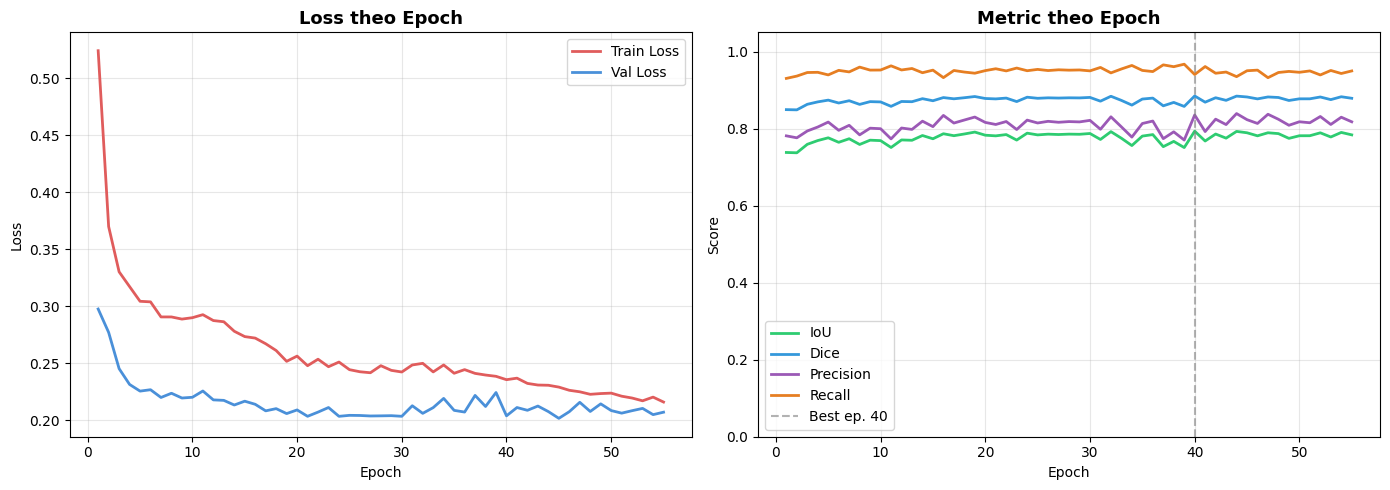

Best ep 40: IoU=0.7934  Dice=0.8848


In [30]:
df_hist = pd.DataFrame(history) if history else pd.read_csv(Path(CONFIG['output_dir']) / 'training_history.csv')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(df_hist['epoch'], df_hist['train_loss'], label='Train Loss', color='#e05c5c', linewidth=2)
ax1.plot(df_hist['epoch'], df_hist['val_loss'],   label='Val Loss',   color='#4a90d9', linewidth=2)
ax1.set_title('Loss theo Epoch', fontsize=13, fontweight='bold')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.legend(); ax1.grid(True, alpha=0.3)

for col, color, label in [
    ('iou',       '#2ecc71', 'IoU'),
    ('dice',      '#3498db', 'Dice'),
    ('precision', '#9b59b6', 'Precision'),
    ('recall',    '#e67e22', 'Recall'),
]:
    ax2.plot(df_hist['epoch'], df_hist[col], label=label, color=color, linewidth=2)

best_row = df_hist.loc[df_hist['iou'].idxmax()]
ax2.axvline(best_row['epoch'], color='gray', linestyle='--', alpha=0.6,
            label=f'Best ep. {int(best_row["epoch"])}')
ax2.set_title('Metric theo Epoch', fontsize=13, fontweight='bold')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Score'); ax2.set_ylim(0, 1.05)
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(str(Path(CONFIG['output_dir']) / 'loss_curve.png'),   dpi=120)
plt.savefig(str(Path(CONFIG['output_dir']) / 'metric_curve.png'), dpi=120)
plt.show()
print(f'Best ep {int(best_row["epoch"])}: IoU={best_row["iou"]:.4f}  Dice={best_row["dice"]:.4f}')

## Cell 10. Evaluation trên tập validation

In [31]:
checkpoint = torch.load(best_model_path, map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f'✓ Load: {best_model_path.name}  (epoch={checkpoint["epoch"]}, IoU={checkpoint["val_iou"]:.4f})')

tp_e = fp_e = fn_e = val_loss_e = 0.0
with torch.no_grad():
    for images_b, masks_b in tqdm(val_loader, desc='Evaluation'):
        images_b = images_b.to(DEVICE)
        masks_b  = masks_b.to(DEVICE)
        logits   = model(images_b)
        val_loss_e += combined_loss(logits, masks_b).item()
        prob  = torch.sigmoid(logits)
        pred  = (prob >= CONFIG['threshold']).float()
        gt    = (masks_b > 0.5).float()
        tp_e += (pred * gt).sum().item()
        fp_e += (pred * (1 - gt)).sum().item()
        fn_e += ((1 - pred) * gt).sum().item()

eps = 1e-6
final_metrics = {
    'model': 'UNet++', 'encoder': CONFIG['encoder_name'],
    'image_size': f'{CONFIG["image_size"][0]}x{CONFIG["image_size"][1]}',
    'threshold': CONFIG['threshold'],
    'val_loss' : val_loss_e / len(val_loader),
    'iou'      : tp_e / (tp_e + fp_e + fn_e + eps),
    'dice'     : 2 * tp_e / (2 * tp_e + fp_e + fn_e + eps),
    'precision': tp_e / (tp_e + fp_e + eps),
    'recall'   : tp_e / (tp_e + fn_e + eps),
}
with open(Path(CONFIG['output_dir']) / 'test_metrics.json', 'w') as f:
    json.dump(final_metrics, f, indent=2)

print('\n── Kết quả Evaluation ─────────────────────────────────')
for k, v in final_metrics.items():
    if isinstance(v, float):
        print(f'  {k:12s}: {v:.4f}')
    else:
        print(f'  {k:12s}: {v}')

✓ Load: unetpp_best_model.pth  (epoch=40, IoU=0.7934)


Evaluation:   0%|          | 0/101 [00:00<?, ?it/s]


── Kết quả Evaluation ─────────────────────────────────
  model       : UNet++
  encoder     : efficientnet-b4
  image_size  : 256x256
  threshold   : 0.5000
  val_loss    : 0.2038
  iou         : 0.7934
  dice        : 0.8848
  precision   : 0.8353
  recall      : 0.9405


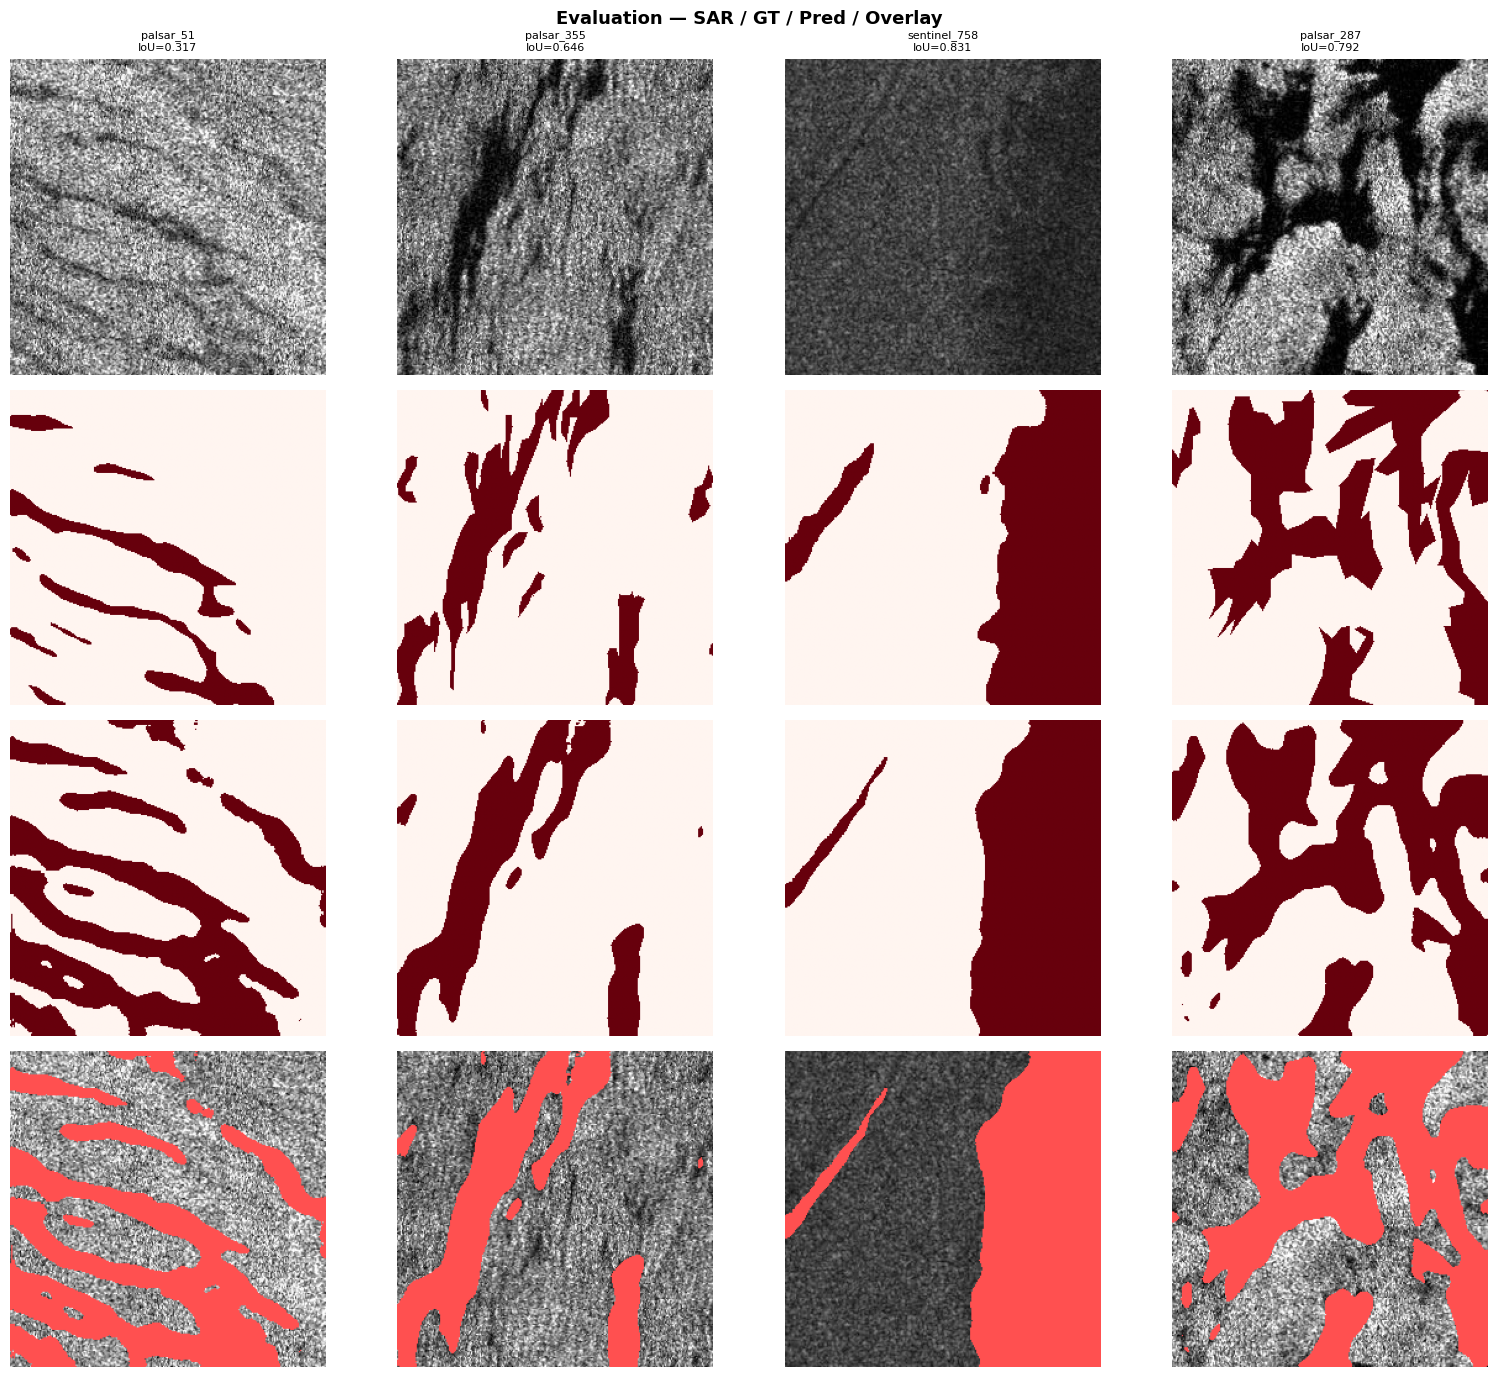

In [32]:
def show_predictions(model, img_paths, mask_paths, n=4, save_path=None):
    indices = random.sample(range(len(img_paths)), min(n, len(img_paths)))
    fig, axes = plt.subplots(4, len(indices), figsize=(4 * len(indices), 14))
    row_labels = ['SAR Image', 'Ground Truth', 'Prediction', 'Overlay']

    model.eval()
    with torch.no_grad():
        for col, idx in enumerate(indices):
            img_bgr = cv2.imread(str(img_paths[idx]))
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            msk     = cv2.imread(str(mask_paths[idx]), cv2.IMREAD_GRAYSCALE)
            gt_bin  = (msk > 127).astype(np.uint8)

            tensor = INFERENCE_TRANSFORM(image=img_rgb)['image'].unsqueeze(0).to(DEVICE)
            prob   = torch.sigmoid(model(tensor)).squeeze().cpu().numpy()
            pred   = (prob >= CONFIG['threshold']).astype(np.uint8)

            gt_256  = cv2.resize(gt_bin,  (256, 256), interpolation=cv2.INTER_NEAREST)
            img_256 = cv2.resize(img_rgb, (256, 256), interpolation=cv2.INTER_LINEAR)
            overlay = img_256.copy()
            overlay[pred == 1] = [255, 80, 80]

            tp = (pred * gt_256).sum()
            iou_s = tp / (pred.sum() + gt_256.sum() - tp + 1e-6)

            for row, data, kw in [
                (0, img_256, {}),
                (1, gt_256,  dict(cmap='Reds', vmin=0, vmax=1)),
                (2, pred,    dict(cmap='Reds', vmin=0, vmax=1)),
                (3, overlay, {}),
            ]:
                axes[row, col].imshow(data, **kw)
                axes[row, col].axis('off')
                if row == 0:
                    axes[row, col].set_title(f'{img_paths[idx].stem[:12]}\nIoU={iou_s:.3f}', fontsize=8)

    for row, label in enumerate(row_labels):
        axes[row, 0].set_ylabel(label, fontsize=10, rotation=0, labelpad=60, va='center')

    fig.suptitle('Evaluation — SAR / GT / Pred / Overlay', fontsize=13, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight')
    plt.show()

show_predictions(
    model, val_imgs, val_masks, n=4,
    save_path=str(Path(CONFIG['output_dir']) / 'test_predictions.png'),
)

## Cell 11. Inference với API thống nhất

API duy nhất `predict(image_path)` — không thêm bất kỳ tham số nào ngoài đường dẫn ảnh.

✓ Model sẵn sàng: unetpp_best_model.pth


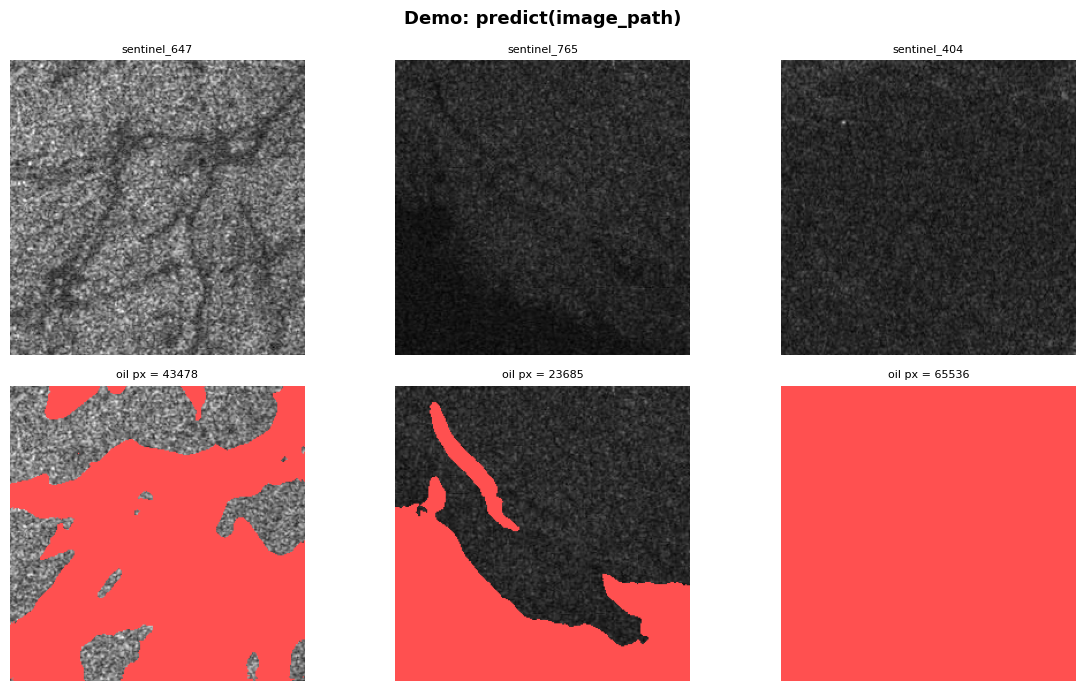

✓ Đã lưu 3 mask vào /kaggle/working/outputs/predictions


In [33]:
checkpoint = torch.load(best_model_path, map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f'✓ Model sẵn sàng: {best_model_path.name}')


def predict(image_path) -> np.ndarray:
    """
    Trả về binary mask uint8 (256, 256) với 0=background và 1=oil spill.

    Args:
        image_path: Đường dẫn ảnh PNG/JPG SAR.

    Returns:
        np.ndarray uint8 shape (256, 256), giá trị {0, 1}.
    """
    img_bgr = cv2.imread(str(image_path))
    if img_bgr is None:
        raise FileNotFoundError(f'Không thể đọc ảnh: {image_path}')
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    tensor  = INFERENCE_TRANSFORM(image=img_rgb)['image'].unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        probability = torch.sigmoid(model(tensor))
    return (probability.squeeze().cpu().numpy() >= CONFIG['threshold']).astype(np.uint8)


# ── Demo inference ──────────────────────────────────────────────────────────────
demo_paths = random.sample(val_imgs, 3)
fig, axes  = plt.subplots(2, 3, figsize=(12, 7))

for col, img_path in enumerate(demo_paths):
    mask_pred = predict(img_path)
    img_bgr   = cv2.imread(str(img_path))
    img_256   = cv2.resize(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB), (256, 256))
    overlay   = img_256.copy()
    overlay[mask_pred == 1] = [255, 80, 80]

    axes[0, col].imshow(img_256)
    axes[0, col].set_title(img_path.stem[:16], fontsize=8)
    axes[0, col].axis('off')
    axes[1, col].imshow(overlay)
    axes[1, col].set_title(f'oil px = {mask_pred.sum()}', fontsize=8)
    axes[1, col].axis('off')

fig.suptitle('Demo: predict(image_path)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(str(Path(CONFIG['output_dir']) / 'inference_demo.png'), dpi=120)
plt.show()

# Lưu mask ra file
pred_dir = Path(CONFIG['output_dir']) / 'predictions'
for img_path in demo_paths:
    mask = predict(img_path)
    cv2.imwrite(str(pred_dir / f'{img_path.stem}_mask.png'), mask * 255)
print(f'✓ Đã lưu {len(demo_paths)} mask vào {pred_dir}')

In [35]:
from pathlib import Path
import torch
import shutil

CHECKPOINT_DIR = Path("/kaggle/working/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

if "model" not in globals():
    raise RuntimeError("Kernel khong con bien model. Neu da restart kernel thi phai train lai moi tao duoc checkpoint.")

iou_value = float(best_iou) if "best_iou" in globals() else 0.0
epoch_value = int(checkpoint["epoch"]) if "checkpoint" in globals() and isinstance(checkpoint, dict) else 0

ckpt_name = f"unetpp_epoch{epoch_value:03d}_iou{iou_value:.4f}.pth"
ckpt_path = CHECKPOINT_DIR / ckpt_name

torch.save({
    "epoch": epoch_value,
    "model_state_dict": model.state_dict(),
    "val_iou": iou_value,
    "config": CONFIG,
    "note": "Manual rescue checkpoint saved after training.",
}, ckpt_path)

export_path = Path("/kaggle/working") / ckpt_name
shutil.copy2(ckpt_path, export_path)

print("Saved checkpoint:", ckpt_path)
print("Copied to:", export_path)
print("Size MB:", export_path.stat().st_size / 1024**2)

Saved checkpoint: /kaggle/working/checkpoints/unetpp_epoch040_iou0.7934.pth
Copied to: /kaggle/working/unetpp_epoch040_iou0.7934.pth
Size MB: 80.19239330291748


---

## Tổng kết artifact

| Artifact | Đường dẫn |
|---|---|
| Best model | `/kaggle/working/checkpoints/unetpp_best_model.pth` |
| Checkpoint | `/kaggle/working/checkpoints/unetpp_efficientnetb4_epoch{n}_iou{score}.pth` |
| Training history | `/kaggle/working/outputs/training_history.csv` |
| EDA samples | `/kaggle/working/outputs/eda_samples.png` |
| Class distribution | `/kaggle/working/outputs/class_distribution.png` |
| Augmentation samples | `/kaggle/working/outputs/augmentation_samples.png` |
| Loss curve | `/kaggle/working/outputs/loss_curve.png` |
| Metric curve | `/kaggle/working/outputs/metric_curve.png` |
| Test metrics | `/kaggle/working/outputs/test_metrics.json` |
| Prediction samples | `/kaggle/working/outputs/test_predictions.png` |
| Inference demo | `/kaggle/working/outputs/inference_demo.png` |
| Prediction masks | `/kaggle/working/outputs/predictions/{stem}_mask.png` |